# Student FULL name:
# Student number:

Acknowledgement Statement by students: <br>
Please keep one acknowledgment from the following<br>
x	I acknowledge that I have not used GenAI (e. g., ChatGPT) in drafting and proofreading of this assignment.<br>
x	I acknowledge that I have only used GenAI (e.g., ChatGPT) in drafting and proofreading this assignment, which is permitted in the assignment instructions. <br>



#  Answer to Section 1 (-2 if not provided) (answer in one cell): 

The possum dataset includes key body measurements such as age, foot length, skull width, and total length, collected from Australian possums. It was used to explore the relationships between these variables and analyze physical variations among possums. Through data cleaning, correlation analysis, and multiple regression, the study aimed to understand how different body features relate to overall body size and identify meaningful biological patterns.

# Answer to Section 2: EDA (15 Marks) - add as many cell as needed

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np 

In [4]:
df = pd.read_csv('possum.csv')
df

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
0,1.0,1.0,Vic,m,8.4,94.1,60.4,89.0,36.0,74.5,54.5,15.2,28.0,36
1,2.0,1.0,Vic,f,6.2,92.5,57.6,91.5,36.5,72.5,51.2,16.0,28.5,33
2,3.0,1.0,Vic,f,6.5,94.0,60,95.5,39.0,75.4,51.9,15.5,30.0,34
3,4.0,1.0,Vic,f,6.6,93.2,57.1,92.0,38.0,76.1,52.2,15.2,28.0,34
4,5.0,1.0,Vic,f,2.1,91.5,56.3,85.5,36.0,71,53.2,15.1,28.5,33
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,100.0,7.0,other,m,1.4,89.5,56,81.5,36.5,66,46.8,14.8,23.0,27
100,101.0,NaN,other,m,1.7,88.6,54.7,82.5,39.0,64.4,48.0,14.0,25.0,33
101,102.0,7.0,other,f,6.4,92.4,55,89.0,38.0,63.5,45.4,13.0,25.0,30
102,103.0,7.0,other,m,4.2,91.5,55.2,82.5,36.5,62.9,45.9,15.4,25.0,29


In [ ]:
## Analyze Dataset

In [7]:
df.shape

(104, 14)

In [9]:
df.head()


,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
0,1.0,1.0,Vic,m,8.4,94.1,60.4,89.0,36.0,74.5,54.5,15.2,28.0,36
1,2.0,1.0,Vic,f,6.2,92.5,57.6,91.5,36.5,72.5,51.2,16.0,28.5,33
2,3.0,1.0,Vic,f,6.5,94.0,60,95.5,39.0,75.4,51.9,15.5,30.0,34
3,4.0,1.0,Vic,f,6.6,93.2,57.1,92.0,38.0,76.1,52.2,15.2,28.0,34
4,5.0,1.0,Vic,f,2.1,91.5,56.3,85.5,36.0,71,53.2,15.1,28.5,33


In [11]:
df.duplicated().sum

<bound method Series.sum of 0      False
1      False
2      False
3      False
4      False
       ...  
99     False
100    False
101    False
102    False
103    False
Length: 104, dtype: bool>

In [13]:
# find out missing value
df.isna().sum()

case        1
site        1
Pop         1
gender      0
age         3
hdlngth     2
skullw      1
totlngth    1
taill       0
footlgth    1
earconch    0
eye         1
chest       0
belly       2
dtype: int64

In [15]:
# These are considered as null values, we should convert the empty cells into na to check all the null values

df = df.replace(['', ' ', '?', 'NA', 'Na', 'na', 'NAN', 'Nan', 'nan'], np.nan)


In [17]:
# as you can see corrected already 


(df.isin(['', ' ', '?', 'NA', 'na']).sum())

case        0
site        0
Pop         0
gender      0
age         0
hdlngth     0
skullw      0
totlngth    0
taill       0
footlgth    0
earconch    0
eye         0
chest       0
belly       0
dtype: int64

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   case      103 non-null    float64
 1   site      103 non-null    float64
 2   Pop       103 non-null    object 
 3   gender    104 non-null    object 
 4   age       101 non-null    object 
 5   hdlngth   102 non-null    float64
 6   skullw    102 non-null    object 
 7   totlngth  103 non-null    float64
 8   taill     104 non-null    float64
 9   footlgth  102 non-null    object 
 10  earconch  104 non-null    float64
 11  eye       103 non-null    float64
 12  chest     104 non-null    float64
 13  belly     101 non-null    object 
dtypes: float64(8), object(6)
memory usage: 11.5+ KB


In [21]:
columns = ['age', 'skullw', 'footlgth', 'belly']
df[columns] = df[columns].apply(pd.to_numeric, errors='coerce')

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   case      103 non-null    float64
 1   site      103 non-null    float64
 2   Pop       103 non-null    object 
 3   gender    104 non-null    object 
 4   age       98 non-null     float64
 5   hdlngth   102 non-null    float64
 6   skullw    102 non-null    float64
 7   totlngth  103 non-null    float64
 8   taill     104 non-null    float64
 9   footlgth  102 non-null    float64
 10  earconch  104 non-null    float64
 11  eye       103 non-null    float64
 12  chest     104 non-null    float64
 13  belly     101 non-null    float64
dtypes: float64(12), object(2)
memory usage: 11.5+ KB


In [25]:
## missing values per row 
row_miss = df[df.isna().any(axis=1)]
row_miss

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
12,13.0,1.0,Vic,m,5.4,95.1,59.9,89.5,36.0,71.0,49.8,15.8,27.0,NaN
14,15.0,1.0,Vic,m,NaN,92.9,57.6,85.5,-22.0,69.7,51.8,15.7,28.0,35.0
15,16.0,1.0,Vic,m,NaN,91.6,56.0,86.0,34.5,73.0,51.4,14.4,28.0,32.0
16,17.0,1.0,Vic,f,1.2,94.7,67.7,NaN,36.5,73.2,53.2,14.7,29.0,31.0
27,28.0,1.0,Vic,m,4.5,NaN,56.8,87.0,34.5,73.2,53.0,15.3,27.0,30.0
37,38.0,2.0,Vic,m,NaN,92.4,56.0,80.5,35.5,68.4,49.5,15.9,27.0,30.0
40,41.0,2.0,Vic,f,5.3,88.4,57.0,83.0,36.5,NaN,40.3,15.9,27.0,30.5
41,42.0,2.0,Vic,m,NaN,85.3,54.1,77.0,32.0,62.7,51.2,13.8,25.5,33.0
43,44.0,2.0,Vic,m,NaN,85.1,51.5,76.0,35.5,70.3,52.6,14.4,23.0,27.0
45,46.0,2.0,Vic,m,NaN,91.4,54.4,84.0,35.0,72.8,51.2,14.4,24.5,35.0


In [27]:
# filled in with " other " for Pop missing value

df_6_0 = df[df['site'] == 6.0]
df_6_0

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
73,74.0,6.0,other,f,4.8,88.7,52.0,83.0,38.0,61.5,45.9,14.7,26.0,34.0
74,75.0,6.0,other,m,6.4,93.8,58.1,89.0,38.0,66.2,45.6,16.9,26.0,33.5
75,76.0,6.0,other,m,5.7,92.4,56.8,89.0,41.0,64.5,46.4,17.8,26.0,33.0
76,77.0,6.0,other,m,6.2,93.6,56.2,84.0,36.0,62.8,42.9,16.2,25.0,35.0
77,78.0,6.0,other,m,1.6,86.5,51.0,81.0,36.5,63.0,44.3,13.2,23.0,28.0
78,79.0,6.0,other,m,1.4,85.8,50.0,81.0,36.5,62.8,43.0,14.8,22.0,28.5
79,80.0,6.0,other,m,1.6,86.7,52.6,84.0,38.0,62.3,44.8,NaN,23.5,30.5
80,81.0,6.0,other,m,3.7,90.6,200.0,85.5,38.0,65.6,41.7,17.0,27.5,35.0
81,82.0,6.0,other,f,4.9,86.0,54.0,82.0,36.5,60.7,42.9,15.4,26.0,32.0
82,83.0,6.0,NaN,f,3.1,NaN,53.8,81.5,36.0,62.0,43.3,14.0,25.0,29.0


In [29]:
pop_6_0_value = df.loc[df['site'] == 6.0, 'Pop'].dropna().iloc[0]

pop_6_0_value

'other'

In [31]:
pop_6_0 = 'other'

# Fill missing Pop values in rows where site == 6.0
df.loc[df['site'] == 6.0, 'Pop'] = df.loc[df['site'] == 6.0, 'Pop'].fillna(pop_6_0)

In [33]:
df_6_0 = df[df['site'] == 6.0]
df_6_0

#as you can see the null values under Pop column has changed to other already

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
73,74.0,6.0,other,f,4.8,88.7,52.0,83.0,38.0,61.5,45.9,14.7,26.0,34.0
74,75.0,6.0,other,m,6.4,93.8,58.1,89.0,38.0,66.2,45.6,16.9,26.0,33.5
75,76.0,6.0,other,m,5.7,92.4,56.8,89.0,41.0,64.5,46.4,17.8,26.0,33.0
76,77.0,6.0,other,m,6.2,93.6,56.2,84.0,36.0,62.8,42.9,16.2,25.0,35.0
77,78.0,6.0,other,m,1.6,86.5,51.0,81.0,36.5,63.0,44.3,13.2,23.0,28.0
78,79.0,6.0,other,m,1.4,85.8,50.0,81.0,36.5,62.8,43.0,14.8,22.0,28.5
79,80.0,6.0,other,m,1.6,86.7,52.6,84.0,38.0,62.3,44.8,NaN,23.5,30.5
80,81.0,6.0,other,m,3.7,90.6,200.0,85.5,38.0,65.6,41.7,17.0,27.5,35.0
81,82.0,6.0,other,f,4.9,86.0,54.0,82.0,36.5,60.7,42.9,15.4,26.0,32.0
82,83.0,6.0,other,f,3.1,NaN,53.8,81.5,36.0,62.0,43.3,14.0,25.0,29.0


In [35]:
# showing the NaN values for site

df[df['site'].isna() | df['Pop'].isna()]


,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
100,101.0,NaN,other,m,1.7,88.6,54.7,82.5,39.0,64.4,48.0,14.0,25.0,33.0


In [37]:
# showing 'other' values of site and Pop columns

df[['site', 'Pop']]

,site,Pop
0,1.0,Vic
1,1.0,Vic
2,1.0,Vic
3,1.0,Vic
4,1.0,Vic
...,...,...
99,7.0,other
100,NaN,other
101,7.0,other
102,7.0,other


In [39]:
# Fill missing 'site' based on 'Pop' group
df.loc[df['site'].isna() & (df['Pop'] == "other"), 'site'] = 7



In [41]:
# Verify the change
df[df['Pop'] == "other"]


,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
46,47.0,3.0,other,m,2.1,90.1,54.8,89.0,37.5,66.0,45.5,15.0,25.0,33.0
47,48.0,3.0,other,m,5.2,98.6,63.2,85.0,34.0,66.9,44.9,17.0,28.0,35.0
48,49.0,3.0,other,m,4.3,95.4,59.2,85.0,37.0,69.0,45.0,15.9,29.5,35.5
49,50.0,3.0,other,f,5.4,91.6,56.4,88.0,38.0,65.0,47.2,14.9,28.0,1230.0
50,51.0,3.0,other,f,5.2,95.6,59.6,85.0,36.0,64.0,43.9,17.4,28.0,38.5
51,52.0,3.0,other,m,6.7,97.6,61.0,93.5,40.0,67.9,44.3,15.8,28.5,32.5
52,53.0,3.0,other,f,3.1,93.1,58.1,91.0,38.0,67.4,46.0,16.5,26.0,33.5
53,54.0,4.0,other,m,7.8,96.9,2500.0,91.5,43.0,71.3,46.0,17.5,30.0,36.5
54,55.0,4.0,other,m,2.6,103.1,63.2,92.5,38.0,72.5,44.9,16.4,30.5,36.0
55,56.0,4.0,other,m,3.8,99.9,61.5,93.7,38.0,68.7,46.8,16.4,27.5,31.5


In [43]:
# Show only rows where 'case' is NaN
df[df['case'].isna()][['case', 'site']]



,case,site
94,NaN,7.0


In [45]:
#fill in missing value

df['case'] = df['case'].fillna(95)


In [47]:
# verify check
df['case'].isna().sum()

0

In [49]:
# after fill in all categorical missing values , we are now going to fill in numerical variables

df.isna().sum()

case        0
site        0
Pop         0
gender      0
age         6
hdlngth     2
skullw      2
totlngth    1
taill       0
footlgth    2
earconch    0
eye         1
chest       0
belly       3
dtype: int64

In [51]:
# For 'age'
# to get all missing values for numerical we can use median

df[df['age'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
14,15.0,1.0,Vic,m,NaN,92.9,57.6,85.5,-22.0,69.7,51.8,15.7,28.0,35.0
15,16.0,1.0,Vic,m,NaN,91.6,56.0,86.0,34.5,73.0,51.4,14.4,28.0,32.0
37,38.0,2.0,Vic,m,NaN,92.4,56.0,80.5,35.5,68.4,49.5,15.9,27.0,30.0
41,42.0,2.0,Vic,m,NaN,85.3,54.1,77.0,32.0,62.7,51.2,13.8,25.5,33.0
43,44.0,2.0,Vic,m,NaN,85.1,51.5,76.0,35.5,70.3,52.6,14.4,23.0,27.0
45,46.0,2.0,Vic,m,NaN,91.4,54.4,84.0,35.0,72.8,51.2,14.4,24.5,35.0


In [53]:
#.reset _index() method is then used to convert this index back intoregular columns, providing a flat dataframe structure

age_median = df.groupby(['site', 'Pop'])['age'].median().reset_index()
age_median


,site,Pop,age
0,1.0,Vic,4.2
1,2.0,Vic,3.2
2,3.0,other,5.2
3,4.0,other,3.7
4,5.0,other,5.4
5,6.0,other,3.4
6,7.0,other,3.7


In [55]:
# Get all existing non-null ages for site 1.0 and Pop 'Vic'
Vic_1_age_values = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'age'
].dropna()


In [57]:
# 1. Calculate median age for site 1 and Pop = 'Vic'

age_1_median = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'), 
    'age'
].dropna().median()

print("Median age for site 1 Vic:", age_1_median)


Median age for site 1 Vic: 4.2


In [59]:
## 2. Replace missing values in 'age' for site 1 and Pop = 'Vic'


df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'age'
] = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'age'
].fillna(age_1_median)

In [61]:
# Get all existing non-null 'age' for site 2.0 and Pop 'Vic'
Vic_2_age_values = df.loc[
    (df['site'] == 2.0) & (df['Pop'] == 'Vic'),
    'age'
].dropna()


In [63]:
# 1. Calculate median 'age' for site 2 and Pop = 'Vic'

age_2_median = df.loc[
    (df['site'] == 2.0) & (df['Pop'] == 'Vic'), 
    'age'
].dropna().median()

print("Median age for site 2 Vic:", age_2_median)

Median age for site 2 Vic: 3.2


In [65]:
# 2. Replace missing values in 'age' for site 2 and Pop = 'Vic'


df.loc[
    (df['site'] == 2.0) & (df['Pop'] == 'Vic'),
    'age'
] = df.loc[
    (df['site'] == 2.0) & (df['Pop'] == 'Vic'),
    'age'
].fillna(age_2_median)

In [67]:
# verify check

df[df['age'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly


In [69]:
# for 'headlength'
df[df['hdlngth'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
27,28.0,1.0,Vic,m,4.5,NaN,56.8,87.0,34.5,73.2,53.0,15.3,27.0,30.0
82,83.0,6.0,other,f,3.1,NaN,53.8,81.5,36.0,62.0,43.3,14.0,25.0,29.0


In [71]:
#.reset _index() method is then used to convert this index back intoregular columns, providing a flat dataframe structure

hdlngth_median = df.groupby(['site', 'Pop'])['hdlngth'].median().reset_index()
hdlngth_median

,site,Pop,hdlngth
0,1.0,Vic,93.75
1,2.0,Vic,90.60
2,3.0,other,95.40
3,4.0,other,96.90
4,5.0,other,92.80
5,6.0,other,88.55
6,7.0,other,92.10


In [73]:
# Get all existing non-null headlength for site 1.0 and Pop 'Vic'
hdlngth_1_values = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'hdlngth'
].dropna()

In [75]:
# Calculate the median hdlngth for site 1.0 and Pop 'Vic'
hdlngth_1_median = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'hdlngth'
].dropna().median()

print("Median headlength for site 1 Vic:", hdlngth_1_median)

Median headlength for site 1 Vic: 93.75


In [77]:
# Replace the missing Value
df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'hdlngth'
] = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'hdlngth'
].fillna(hdlngth_1_median)

In [79]:
# Get all existing non-null headlength for site 6.0 and Pop 'Other'
hdlngth_1_values = df.loc[
    (df['site'] == 6.0) & (df['Pop'] == 'Vic'),
    'hdlngth'
].dropna()

In [81]:
# Calculate the median hdlngth for site 6.0 and Pop 'Other'
hdlngth_6_median = df.loc[
    (df['site'] == 6.0) & (df['Pop'] == 'other'),
    'hdlngth'
].dropna().median()

print("Median headlength for site 6 other:", hdlngth_6_median)

Median headlength for site 6 other: 88.55000000000001


In [85]:
#Replace the missing value

df.loc[
    (df['site'] == 6.0) & (df['Pop'] == 'other'),
    'hdlngth'
] = df.loc[
    (df['site'] == 6.0) & (df['Pop'] == 'other'),
    'hdlngth'
].fillna(hdlngth_6_median)

In [87]:
# Verify if missing values are filled or if there's still NaN

df[df['hdlngth'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly


In [89]:
# for 'skullWidth'
df[df['skullw'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
57,58.0,4.0,other,m,3.7,94.5,NaN,91.0,39.0,66.5,-14.0,14.4,30.5,33.0
86,87.0,7.0,other,m,2.3,98.5,NaN,93.0,41.5,71.7,46.8,15.0,26.0,36.0


In [91]:
#.reset _index() method is then used to convert this index back intoregular columns, providing a flat dataframe structure
skullw_median = df.groupby(['site', 'Pop'])['skullw'].median().reset_index()
skullw_median

,site,Pop,skullw
0,1.0,Vic,56.80
1,2.0,Vic,55.50
2,3.0,other,59.20
3,4.0,other,62.15
4,5.0,other,56.40
5,6.0,other,54.00
6,7.0,other,56.20


In [93]:
# Get all existing non-null skullw for site 4.0 and Pop 'other'
skullw_4_values = df.loc[
    (df['site'] == 4.0) & (df['Pop'] == 'other'),
    'skullw'
].dropna()

In [95]:
# Calculate the median skullw for site 4.0 and Pop 'other'
skullw_4_median = df.loc[
    (df['site'] == 4.0) & (df['Pop'] == 'other'),
    'skullw'
].dropna().median()

print("Median skullw for site 4 other:", skullw_4_median)

Median skullw for site 4 other: 62.15


In [97]:
# Replace the missing Value
df.loc[
    (df['site'] == 4.0) & (df['Pop'] == 'other'),
    'skullw'
] = df.loc[
    (df['site'] == 4.0) & (df['Pop'] == 'other'),
    'skullw'
].fillna(skullw_4_median)

In [99]:
# Get all existing non-null skullw for site 7.0 and Pop 'other'
skullw_7_values = df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'skullw'
].dropna()

In [101]:
# Calculate the median skullw for site 7.0 and Pop 'other'
skullw_7_median = df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'skullw'
].dropna().median()

print("Median skullw for site 7 other:", skullw_7_median)

Median skullw for site 7 other: 56.2


In [103]:
# Replace the missing Value
df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'skullw'
] = df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'skullw'
].fillna(skullw_7_median)

In [105]:
# Verify if missing values are filled or if there's still NaN

df[df['hdlngth'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly


In [107]:
# for 'total length'
df[df['totlngth'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
16,17.0,1.0,Vic,f,1.2,94.7,67.7,NaN,36.5,73.2,53.2,14.7,29.0,31.0


In [109]:
#.reset _index() method is then used to convert this index back intoregular columns, providing a flat dataframe structure
totlngth_median = df.groupby(['site', 'Pop'])['totlngth'].median().reset_index()
totlngth_median

,site,Pop,totlngth
0,1.0,Vic,89.75
1,2.0,Vic,82.50
2,3.0,other,88.00
3,4.0,other,92.50
4,5.0,other,88.00
5,6.0,other,84.00
6,7.0,other,85.00


In [111]:
# Get all existing non-null totlngth for site 1.0 and Pop 'Vic'
totlngth_1_values = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'totlngth'
].dropna()

In [113]:
# Calculate the median skullw for site 1.0 and Pop 'Vic'
totlngth_1_median = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'totlngth'
].dropna().median()

print("Median totlngth for site 1 Vic:", totlngth_1_median)

Median totlngth for site 1 Vic: 89.75


In [115]:
# Replace the missing Value
df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'totlngth'
] = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'totlngth'
].fillna(totlngth_1_median)

In [117]:
# Verify if missing values are filled or if there's still NaN

df[df['totlngth'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly


In [119]:
# for 'footlength'
df[df['footlgth'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
40,41.0,2.0,Vic,f,5.3,88.4,57.0,83.0,36.5,NaN,40.3,15.9,27.0,30.5
94,95.0,7.0,other,m,4.3,91.6,56.6,88.5,37.5,NaN,45.4,14.9,27.0,31.0


In [121]:
#.reset _index() method is then used to convert this index back intoregular columns, providing a flat dataframe structure
footlgth_median = df.groupby(['site', 'Pop'])['footlgth'].median().reset_index()
footlgth_median

,site,Pop,footlgth
0,1.0,Vic,73.20
1,2.0,Vic,71.35
2,3.0,other,66.90
3,4.0,other,68.70
4,5.0,other,65.00
5,6.0,other,62.80
6,7.0,other,65.50


In [123]:
# Get all existing non-null footlgth for site 2.0 and Pop 'Vic'
footlgth_2_values = df.loc[
    (df['site'] == 2.0) & (df['Pop'] == 'Vic'),
    'footlgth'
].dropna()

In [125]:
# Calculate the median footlgth for site 2.0 and Pop 'Vic'
footlgth_2_median = df.loc[
    (df['site'] == 2.0) & (df['Pop'] == 'Vic'),
    'footlgth'
].dropna().median()

print("Median footlgth for site 2 Vic:", footlgth_2_median)

Median footlgth for site 2 Vic: 71.35


In [129]:
# Replace the missing Value
df.loc[
    (df['site'] == 2.0) & (df['Pop'] == 'Vic'),
    'footlgth'
] = df.loc[
    (df['site'] == 2.0) & (df['Pop'] == 'Vic'),
    'footlgth'
].fillna(footlgth_2_median)

In [131]:
# Get all existing non-null footlgth for site 7.0 and Pop 'other'
footlgth_7_values = df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'footlgth'
].dropna()

In [133]:
# Calculate the median footlgth for site 7.0 and Pop 'other'
footlgth_7_median = df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'footlgth'
].dropna().median()

print("Median footlgth for site 7 other:", footlgth_7_median)

Median footlgth for site 7 other: 65.5


In [135]:
# Replace the missing Value
df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'footlgth'
] = df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'footlgth'
].fillna(footlgth_7_median)

In [137]:
# Verify if missing values are filled or if there's still NaN

df[df['footlgth'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly


In [ ]:
# Find and fix missing value for eye

In [139]:
#.reset _index() method is then used to convert this index back intoregular columns, providing a flat dataframe structure
eye_median = df.groupby(['site', 'Pop'])['eye'].median().reset_index()
eye_median

,site,Pop,eye
0,1.0,Vic,15.1
1,2.0,Vic,14.4
2,3.0,other,15.9
3,4.0,other,14.7
4,5.0,other,15.2
5,6.0,other,15.1
6,7.0,other,14.5


In [141]:
# Get all existing non-null eye  for site 6.0 and Pop 'other'
eye_6__values = df.loc[
    (df['site'] == 6.0) & (df['Pop'] == 'other'),
    'eye'
].dropna()

In [143]:
# Calculate the median eye for site 6.0 and Pop 'other'
eye_6_median = df.loc[
    (df['site'] == 6.0) & (df['Pop'] == 'other'),
    'eye'
].dropna().median()

print("Median eye for site 6 other:", eye_6_median)

Median eye for site 6 other: 15.100000000000001


In [145]:
# Replace the missing Value
df.loc[
    (df['site'] == 6.0) & (df['Pop'] == 'other'),
    'eye'
] = df.loc[
    (df['site'] == 6.0) & (df['Pop'] == 'other'),
    'eye'
].fillna(eye_6_median)

In [147]:
# Verify if missing values are filled or if there's still NaN

df[df['eye'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly


In [149]:
#Find and fix missing values for belly

df[df['belly'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
12,13.0,1.0,Vic,m,5.4,95.1,59.9,89.5,36.0,71.0,49.8,15.8,27.0,NaN
89,90.0,7.0,other,m,3.5,92.6,54.6,85.0,38.5,1500.0,44.8,14.5,25.5,NaN
92,93.0,7.0,other,m,3.8,89.2,54.0,82.0,38.0,63.8,44.9,12.8,24.0,NaN


In [151]:
#.reset _index() method is then used to convert this index back intoregular columns, providing a flat dataframe structure
belly_median = df.groupby(['site', 'Pop'])['belly'].median().reset_index()
belly_median

,site,Pop,belly
0,1.0,Vic,33.00
1,2.0,Vic,31.00
2,3.0,other,35.00
3,4.0,other,36.00
4,5.0,other,32.00
5,6.0,other,31.50
6,7.0,other,31.75


In [153]:
# Get all existing non-null belly for site 1.0 and Pop 'Vic'
belly_1__values = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'belly'
].dropna()

In [155]:
# Calculate the median belly for site 6.0 and Pop 'other'
belly_1_median = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'belly'
].dropna().median()

print("Median belly for site 1 other:", belly_1_median)

Median belly for site 1 other: 33.0


In [157]:
# Replace the missing Value
df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'belly'
] = df.loc[
    (df['site'] == 1.0) & (df['Pop'] == 'Vic'),
    'belly'
].fillna(belly_1_median)

In [159]:
# Get all existing non-null belly for site 7.0 and Pop 'other'
belly_7__values = df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'belly'
].dropna()

In [161]:
# Calculate the median belly for site 7.0 and Pop 'other'
belly_7_median = df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'belly'
].dropna().median()

print("Median belly for site 7 other:", belly_7_median)

Median belly for site 7 other: 31.75


In [163]:
# Replace the missing Value
df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'belly'
] = df.loc[
    (df['site'] == 7.0) & (df['Pop'] == 'other'),
    'belly'
].fillna(belly_7_median)

In [165]:
# Verify if missing values are filled or if there's still NaN

df[df['belly'].isna()]

,case,site,Pop,gender,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly


In [167]:
# verify check 

df.isna().sum()

# no missing values anymore , already fixed

case        0
site        0
Pop         0
gender      0
age         0
hdlngth     0
skullw      0
totlngth    0
taill       0
footlgth    0
earconch    0
eye         0
chest       0
belly       0
dtype: int64

In [ ]:
## check unique values

In [170]:
df.shape

(104, 14)

In [174]:
print(sorted(df['age'].dropna().unique()))

#as we can see that there are some used (,) instead of (.)

[1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4.1, 4.2, 4.3, 4.5, 4.6, 4.7, 4.8, 4.9, 5.2, 5.3, 5.4, 5.7, 5.8, 5.9, 6.1, 6.2, 6.3, 6.4, 6.5, 6.6, 6.7, 6.8, 6.9, 7.2, 7.3, 7.4, 7.6, 7.8, 7.9, 8.4, 9.3, 9.4]


In [176]:
# fixing it

df['age'] = df['age'].astype(str).str.replace(',', '.').astype(float)


In [178]:
print(sorted(df['age'].dropna().unique()))

[1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4.1, 4.2, 4.3, 4.5, 4.6, 4.7, 4.8, 4.9, 5.2, 5.3, 5.4, 5.7, 5.8, 5.9, 6.1, 6.2, 6.3, 6.4, 6.5, 6.6, 6.7, 6.8, 6.9, 7.2, 7.3, 7.4, 7.6, 7.8, 7.9, 8.4, 9.3, 9.4]


In [180]:
# Check unique values
print(df['taill'].unique())

# tehre are some floats have (-) sign

[ 36.   36.5  39.   38.   35.5  37.   37.5 -22.   34.5  35.   39.5  34.
  33.5  32.   40.   43.   41.   38.5  40.5  41.5]


In [182]:
# fix it

df['taill'] = df['taill'].abs()

In [184]:
# verify check

print(df['taill'].unique())

[36.  36.5 39.  38.  35.5 37.  37.5 22.  34.5 35.  39.5 34.  33.5 32.
 40.  43.  41.  38.5 40.5 41.5]


In [186]:
# Check unique values
print(df['belly'].unique())

# there are some floats have (-) sign

[  36.     33.     34.     32.     34.5   -12.     31.5    35.     31.
   40.     38.     28.     30.     28.5    35.5    25.     30.5    27.
 1230.     38.5    32.5    33.5    36.5    39.     29.5    29.     31.75]


In [188]:
# fix it

df['belly'] = df['belly'].abs()

In [190]:
# verify check

print(df['belly'].unique())

[  36.     33.     34.     32.     34.5    12.     31.5    35.     31.
   40.     38.     28.     30.     28.5    35.5    25.     30.5    27.
 1230.     38.5    32.5    33.5    36.5    39.     29.5    29.     31.75]


In [192]:
# Check unique values
print(df['earconch'].unique())

# there are some floats have (-) sign

[ 54.5  51.2  51.9  52.2  53.2  53.6  52.   53.9  52.9  53.4  51.3  51.
  49.8  53.7  51.8  51.4  55.4  52.4  52.1  53.3  53.5  51.6  56.2  50.8
  53.   52.5  53.1  55.5  49.5  40.3  49.4  52.6  54.   45.5  44.9  45.
  47.2  43.9  44.3  46.   46.8  45.3 -14.   44.5  47.   41.3  46.3  45.1
  41.7  44.2  44.1  43.1  45.6  42.8  42.4  44.7  45.9  46.4  42.9  43.
  44.8  43.3  43.6  43.5  43.7  46.2  48.   45.4  47.7  43.8]


In [196]:
# fix it

df['earconch'] = df['earconch'].abs()

In [198]:
# verify check

print(df['earconch'].unique())

[54.5 51.2 51.9 52.2 53.2 53.6 52.  53.9 52.9 53.4 51.3 51.  49.8 53.7
 51.8 51.4 55.4 52.4 52.1 53.3 53.5 51.6 56.2 50.8 53.  52.5 53.1 55.5
 49.5 40.3 49.4 52.6 54.  45.5 44.9 45.  47.2 43.9 44.3 46.  46.8 45.3
 14.  44.5 47.  41.3 46.3 45.1 41.7 44.2 44.1 43.1 45.6 42.8 42.4 44.7
 45.9 46.4 42.9 43.  44.8 43.3 43.6 43.5 43.7 46.2 48.  45.4 47.7 43.8]


In [200]:
# Show all column names
df.columns
# the heads are not clear

Index(['case', 'site', 'Pop', 'gender', 'age', 'hdlngth', 'skullw', 'totlngth',
       'taill', 'footlgth', 'earconch', 'eye', 'chest', 'belly'],
      dtype='object')

In [202]:
# Full column name corrections
col_corrections = {
    'case': 'Case',
    'site': 'Site',
    'Pop': 'Population',
    'gender': 'Gender',
    'age': 'Age',
    'hdlngth': 'HeadLength',
    'skullw': 'SkullWidth',
    'totlngth': 'TotalLength',
    'taill': 'TailLength',
    'footlgth': 'FootLength',
    'earconch': 'EarConch',
    'eye': 'Eye',
    'chest': 'Chest',
    'belly': 'Belly'
}

# Apply renaming
df = df.rename(columns=col_corrections)


In [204]:
# Already changed with the correct column names
df.columns


Index(['Case', 'Site', 'Population', 'Gender', 'Age', 'HeadLength',
       'SkullWidth', 'TotalLength', 'TailLength', 'FootLength', 'EarConch',
       'Eye', 'Chest', 'Belly'],
      dtype='object')

In [ ]:
## Outliers

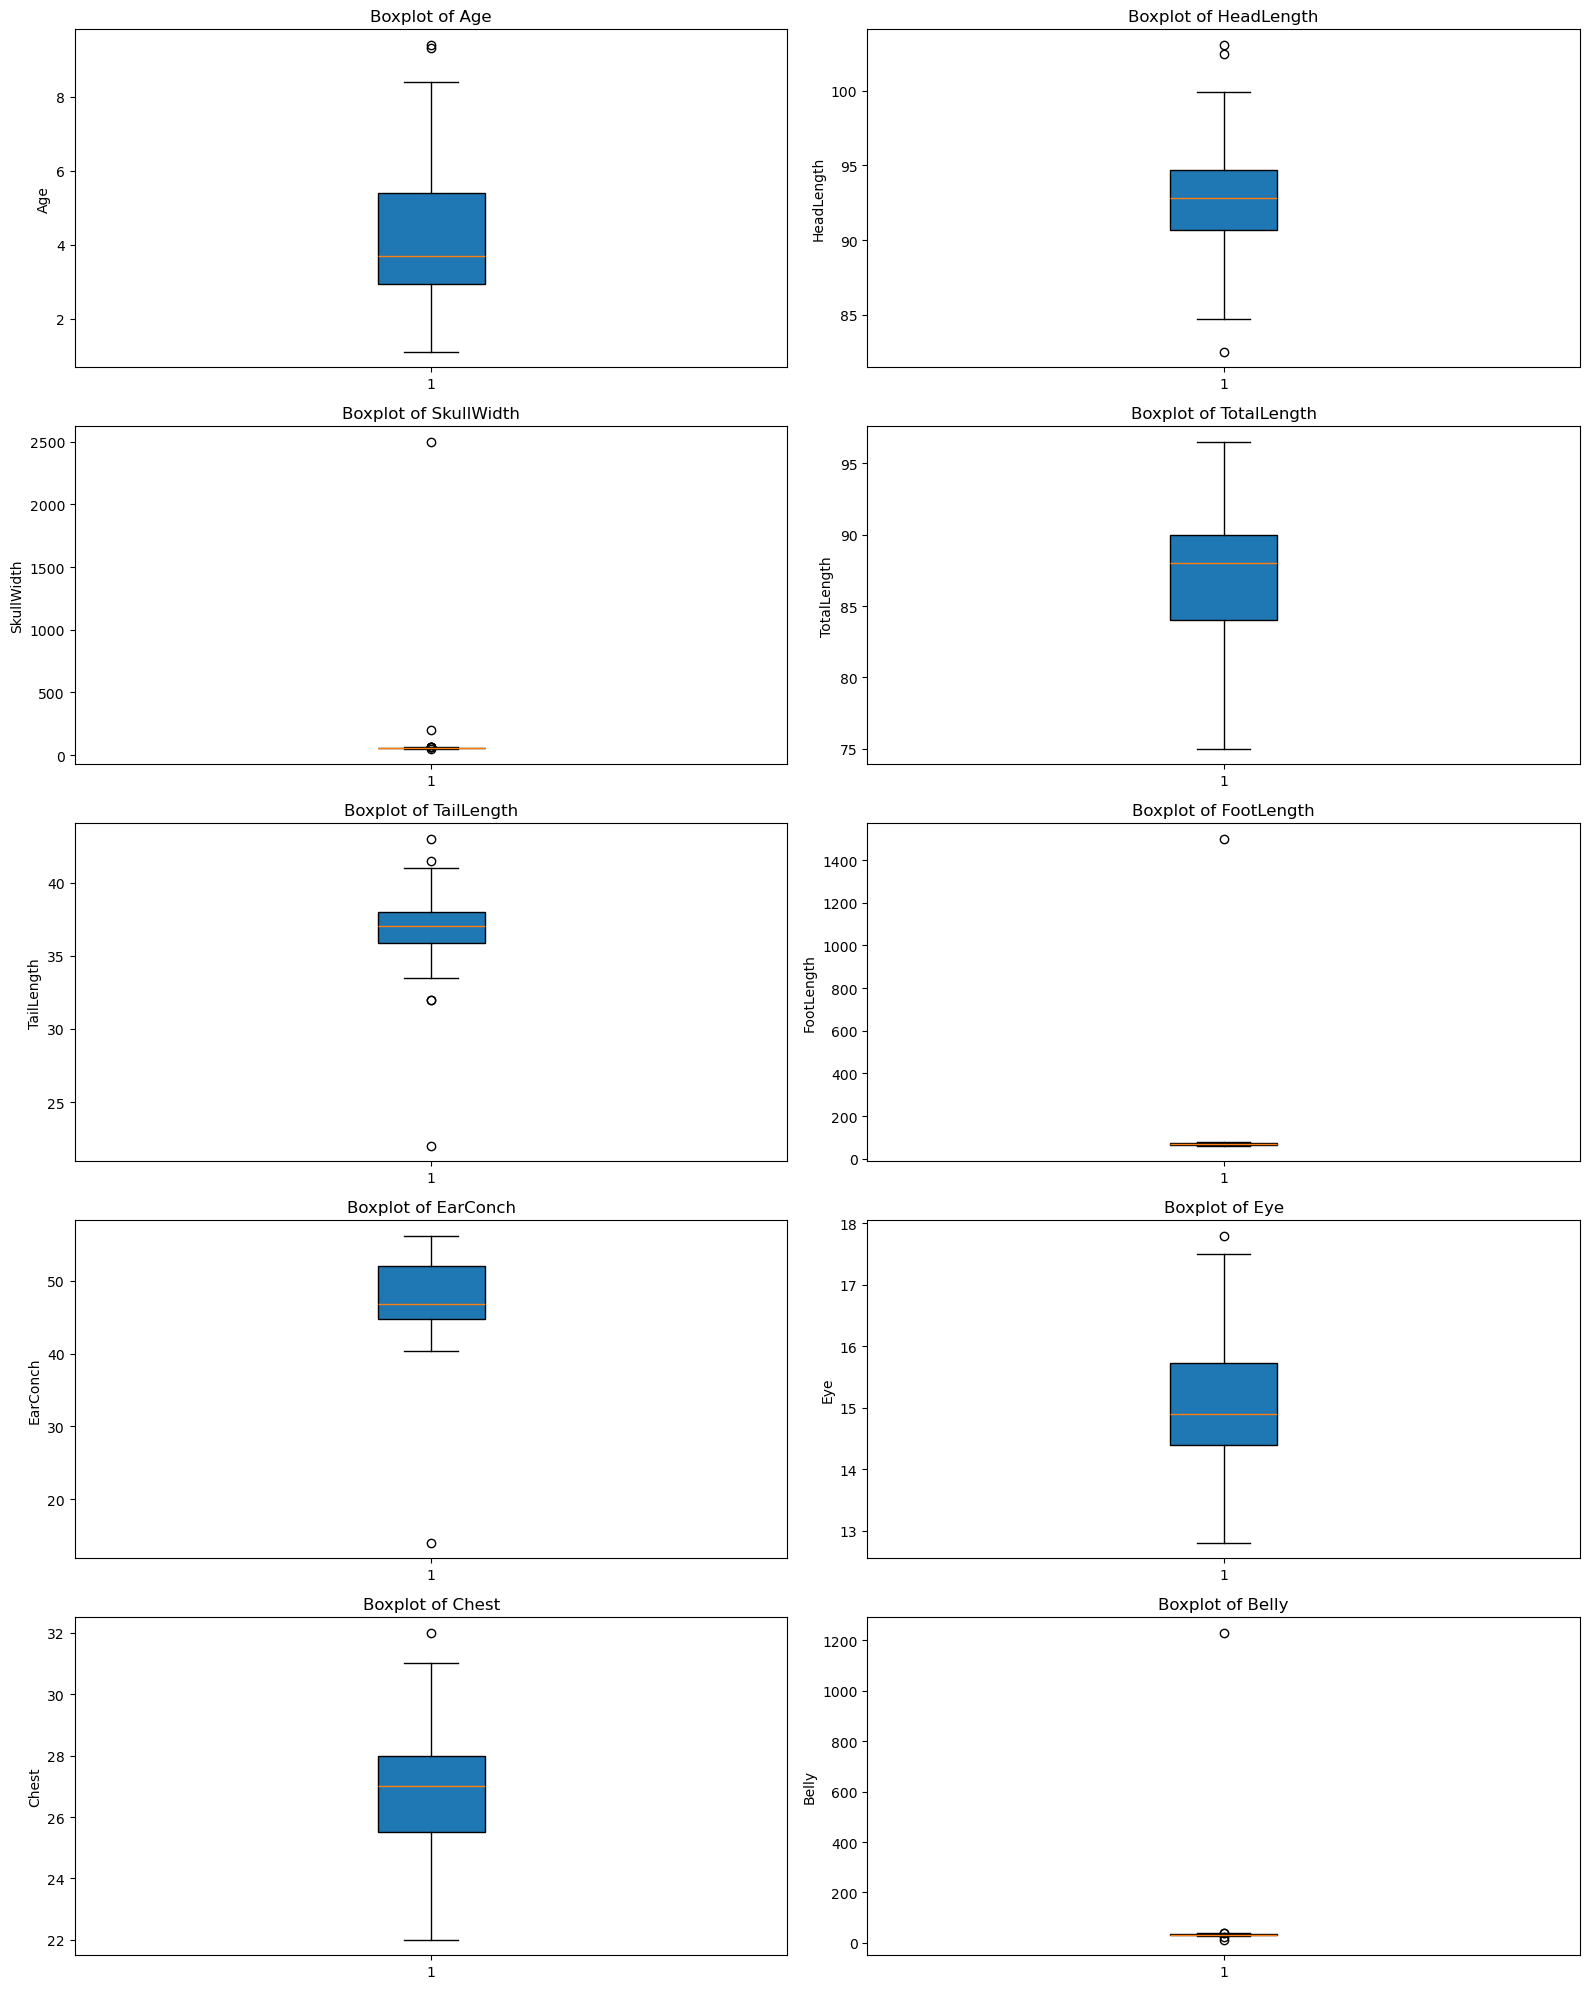

,Case,Site,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly
count,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000
mean,52.500000,3.625000,4.176923,92.589423,81.638462,87.091346,36.894231,82.249038,47.819231,15.047115,27.000000,43.866346
std,30.166206,2.349086,1.908043,3.585865,239.872324,4.312279,2.434255,140.439770,5.298087,1.050377,2.045597,117.488321
min,1.000000,1.000000,1.100000,82.500000,50.000000,75.000000,22.000000,60.300000,14.000000,12.800000,22.000000,12.000000
25%,26.750000,1.000000,2.925000,90.675000,54.975000,84.000000,35.875000,64.775000,44.775000,14.400000,25.500000,31.000000
50%,52.500000,3.000000,3.700000,92.800000,56.350000,88.000000,37.000000,68.100000,46.800000,14.900000,27.000000,32.250000
75%,78.250000,6.000000,5.400000,94.725000,58.100000,90.000000,38.000000,72.550000,52.000000,15.725000,28.000000,34.125000
max,104.000000,7.000000,9.400000,103.100000,2500.000000,96.500000,43.000000,1500.000000,56.200000,17.800000,32.000000,1230.000000


In [209]:
# Create boxplots to identify outliers

# Round all numeric columns to 1 decimal place
df = df.round(1)


# Create boxplot for Age
plt.figure(figsize=(16, 20))  # Bigger figure for 10 plots

# Age
plt.subplot(5, 2, 1)
plt.boxplot(df['Age'], patch_artist=True)
plt.title('Boxplot of Age')
plt.ylabel('Age')

# HeadLength
plt.subplot(5, 2, 2)
plt.boxplot(df['HeadLength'], patch_artist=True)
plt.title('Boxplot of HeadLength')
plt.ylabel('HeadLength')

# SkullWidth
plt.subplot(5, 2, 3)
plt.boxplot(df['SkullWidth'], patch_artist=True)
plt.title('Boxplot of SkullWidth')
plt.ylabel('SkullWidth')

# TotalLength
plt.subplot(5, 2, 4)
plt.boxplot(df['TotalLength'], patch_artist=True)
plt.title('Boxplot of TotalLength')
plt.ylabel('TotalLength')

# TailLength
plt.subplot(5, 2, 5)
plt.boxplot(df['TailLength'], patch_artist=True)
plt.title('Boxplot of TailLength')
plt.ylabel('TailLength')

# FootLength
plt.subplot(5, 2, 6)
plt.boxplot(df['FootLength'], patch_artist=True)
plt.title('Boxplot of FootLength')
plt.ylabel('FootLength')

# EarConch
plt.subplot(5, 2, 7)
plt.boxplot(df['EarConch'], patch_artist=True)
plt.title('Boxplot of EarConch')
plt.ylabel('EarConch')

# Eye
plt.subplot(5, 2, 8)
plt.boxplot(df['Eye'], patch_artist=True)
plt.title('Boxplot of Eye')
plt.ylabel('Eye')

# Chest
plt.subplot(5, 2, 9)
plt.boxplot(df['Chest'], patch_artist=True)
plt.title('Boxplot of Chest')
plt.ylabel('Chest')

# Belly
plt.subplot(5, 2, 10)
plt.boxplot(df['Belly'], patch_artist=True)
plt.title('Boxplot of Belly')
plt.ylabel('Belly')

plt.tight_layout()
plt.show()


df.describe()


In [ ]:
# Outliers for 'Belly'

In [221]:
# Calculate 25th percentile of TailLength
percentile25 = df['Belly'].quantile(0.25)
print('percentile25 ', percentile25)

# Calculate 75th percentile of TailLength
percentile75 = df['Belly'].quantile(0.75)
print('percentile75 ', percentile75)



percentile25  31.0
percentile75  34.125


In [223]:
# Calculate interquartile range
iqr = percentile75 - percentile25
print('IQR:', iqr)

# Calculate upper and lower thresholds for outliers
upper_limit = percentile75 + 1.5 * iqr
lower_limit = percentile25 - 1.5 * iqr
print('Upper limit is: ' + str(upper_limit))
print('Lower limit is: ' + str(lower_limit))



IQR: 3.125
Upper limit is: 38.8125
Lower limit is: 26.3125


In [225]:
# Isolate outliers on low end


df[df['Belly'] < lower_limit]



,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly
7,8.0,1.0,Vic,f,6.3,94.8,57.6,91.0,37.0,72.7,53.9,14.5,29.0,12.0
38,39.0,2.0,Vic,f,1.3,84.7,51.5,75.0,34.0,68.7,53.4,13.0,25.0,25.0


In [227]:
#fix the outliers by replacing them with median
#outliers = [12.0, 25.0]

# Calculate median of TailLength
median_Belly = df['Belly'].median()
print('Median Belly:', median_Belly)

# Replace high-end outliers with median
df['Belly'].replace(12.0, median_Belly, inplace=True)
df['Belly'].replace(25.0, median_Belly, inplace=True)


Median Belly: 32.25


C:\Users\bienk\AppData\Local\Temp\ipykernel_19804\1924723229.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Belly'].replace(12.0, median_Belly, inplace=True)
C:\Users\bienk\AppData\Local\Temp\ipykernel_19804\1924723229.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

Fo

In [229]:
# Isolate outliers on upper end
df_upper = df[df['Belly'] > upper_limit]


df_upper

,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly
20,21.0,1.0,Vic,f,3.6,95.9,58.1,96.5,39.5,77.9,52.9,14.2,30.0,40.0
49,50.0,3.0,other,f,5.4,91.6,56.4,88.0,38.0,65.0,47.2,14.9,28.0,1230.0
56,57.0,4.0,other,f,4.1,95.1,59.4,93.0,41.0,67.2,45.3,14.5,31.0,39.0


In [231]:
outliers = df_upper['Belly'].tolist()
outliers

#outliers = [40.0, 1230.0, 39.0]


df['Belly'].replace(outliers, median_Belly, inplace=True)



C:\Users\bienk\AppData\Local\Temp\ipykernel_19804\3634074808.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Belly'].replace(outliers, median_Belly, inplace=True)


In [233]:
# to check if we replaced the outlier: 
#isolate outliers on low end
df[df['Belly'] < lower_limit]
#now we can see the outliers

,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly


In [235]:
#isolate th eoutlier on upper end:
df[df['Belly'] > upper_limit]
#now we can see the outliers

,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly


In [ ]:
# Outliers for 'SkullWidth'

In [237]:
# Calculate 25th percentile of 'SkullWidth'
percentile25 = df['SkullWidth'].quantile(0.25)
print('percentile25 ', percentile25)

# Calculate 75th percentile of 'SkullWidth'
percentile75 = df['SkullWidth'].quantile(0.75)
print('percentile75 ', percentile75)

percentile25  54.975
percentile75  58.1


In [239]:
# Calculate interquartile range
iqr = percentile75 - percentile25
print('IQR:', iqr)

# Calculate upper and lower thresholds for outliers
upper_limit = percentile75 + 1.5 * iqr
lower_limit = percentile25 - 1.5 * iqr
print('Upper limit is: ' + str(upper_limit))
print('Lower limit is: ' + str(lower_limit))

IQR: 3.125
Upper limit is: 62.7875
Lower limit is: 50.2875


In [241]:
# Isolate outliers on low end


df[df['SkullWidth'] < lower_limit]


,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly
78,79.0,6.0,other,m,1.4,85.8,50.0,81.0,36.5,62.8,43.0,14.8,22.0,28.5


In [247]:
#fix the outliers by replacing them with median
#outliers = [50.0]

# Calculate median of TailLength
median_SkullWidth = df['SkullWidth'].median()
print('Median SkullWidth:', median_SkullWidth)

# Replace high-end outliers with median
df['SkullWidth'].replace(50.0, median_SkullWidth, inplace=True)




Median SkullWidth: 56.349999999999994


C:\Users\bienk\AppData\Local\Temp\ipykernel_19804\3311115118.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['SkullWidth'].replace(50.0, median_SkullWidth, inplace=True)


In [249]:
# Isolate outliers on upper end
df_upper = df[df['SkullWidth'] > upper_limit]


df_upper

,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly
16,17.0,1.0,Vic,f,1.2,94.7,67.7,89.8,36.5,73.2,53.2,14.7,29.0,31.0
47,48.0,3.0,other,m,5.2,98.6,63.2,85.0,34.0,66.9,44.9,17.0,28.0,35.0
53,54.0,4.0,other,m,7.8,96.9,2500.0,91.5,43.0,71.3,46.0,17.5,30.0,36.5
54,55.0,4.0,other,m,2.6,103.1,63.2,92.5,38.0,72.5,44.9,16.4,30.5,36.0
58,59.0,4.0,other,m,2.3,102.5,62.8,96.0,40.0,73.2,44.5,14.7,32.0,36.0
80,81.0,6.0,other,m,3.7,90.6,200.0,85.5,38.0,65.6,41.7,17.0,27.5,35.0
97,98.0,7.0,other,m,5.2,93.2,68.6,84.0,35.0,65.6,44.3,14.5,28.5,32.0


In [251]:
outliers = df_upper['SkullWidth'].tolist()
outliers

#outliers = [67.7, 63.2, 2500.0, 53.2, 62.8, 200.0, 68.6]


df['SkullWidth'].replace(outliers, median_SkullWidth, inplace=True)


C:\Users\bienk\AppData\Local\Temp\ipykernel_19804\3243012781.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['SkullWidth'].replace(outliers, median_SkullWidth, inplace=True)


In [253]:
# to check if we replaced the outlier: 
#isolate outliers on low end
df[df['SkullWidth'] < lower_limit]
#now we can see the outliers

,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly


In [255]:
#isolate th eoutlier on upper end:
df[df['SkullWidth'] > upper_limit]
#now we can see the outliers

,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly


In [ ]:
# Outliers for 'SkullWidth'

In [259]:
# Calculate 25th percentile of FootLength	
percentile25 = df['FootLength'].quantile(0.25)
print('percentile25 ', percentile25)

# Calculate 75th percentile of FootLength	
percentile75 = df['FootLength'].quantile(0.75)
print('percentile75 ', percentile75)

percentile25  64.775
percentile75  72.55


In [261]:
# Calculate interquartile range
iqr = percentile75 - percentile25
print('IQR:', iqr)

# Calculate upper and lower thresholds for outliers
upper_limit = percentile75 + 1.5 * iqr
lower_limit = percentile25 - 1.5 * iqr
print('Upper limit is: ' + str(upper_limit))
print('Lower limit is: ' + str(lower_limit))

IQR: 7.7749999999999915
Upper limit is: 84.21249999999998
Lower limit is: 53.11250000000002


In [263]:
# Isolate outliers on low end


df[df['FootLength'] < lower_limit]

# it means there's no outliers for lower limit

,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly


In [265]:
# Isolate outliers on upper end
df_upper = df[df['FootLength'] > upper_limit]


df_upper

,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly
89,90.0,7.0,other,m,3.5,92.6,54.6,85.0,38.5,1500.0,44.8,14.5,25.5,31.8


In [267]:
outliers = df_upper['FootLength'].tolist()
outliers

# outliers = [1500.0]

df['FootLength'].replace(outliers, median_SkullWidth, inplace=True)



C:\Users\bienk\AppData\Local\Temp\ipykernel_19804\3432388821.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['FootLength'].replace(outliers, median_SkullWidth, inplace=True)


In [269]:
# to check if we replaced the outlier: 
#isolate outliers on low end
df[df['FootLength'] < lower_limit]
#now we can see the outliers

,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly


In [271]:
#isolate th eoutlier on upper end:
df[df['FootLength'] > upper_limit]
#now we can see the outliers

,Case,Site,Population,Gender,Age,HeadLength,SkullWidth,TotalLength,TailLength,FootLength,EarConch,Eye,Chest,Belly


In [ ]:
## Skewness

In [286]:
# Calculating skewness before transformation
skewness_possum = df[['HeadLength', 'SkullWidth', 'TailLength', 'FootLength', 'Belly', 'Eye', 'Age', 'EarConch', 'Chest', 'TotalLength']].skew()


print("Skewness of possum:", skewness_possum)

Skewness of possum: HeadLength    -0.053890
SkullWidth    -0.003154
TailLength    -2.069263
FootLength    -0.037647
Belly          0.061283
Eye            0.389940
Age            0.607979
EarConch      -2.393873
Chest         -0.055511
TotalLength   -0.286239
dtype: float64


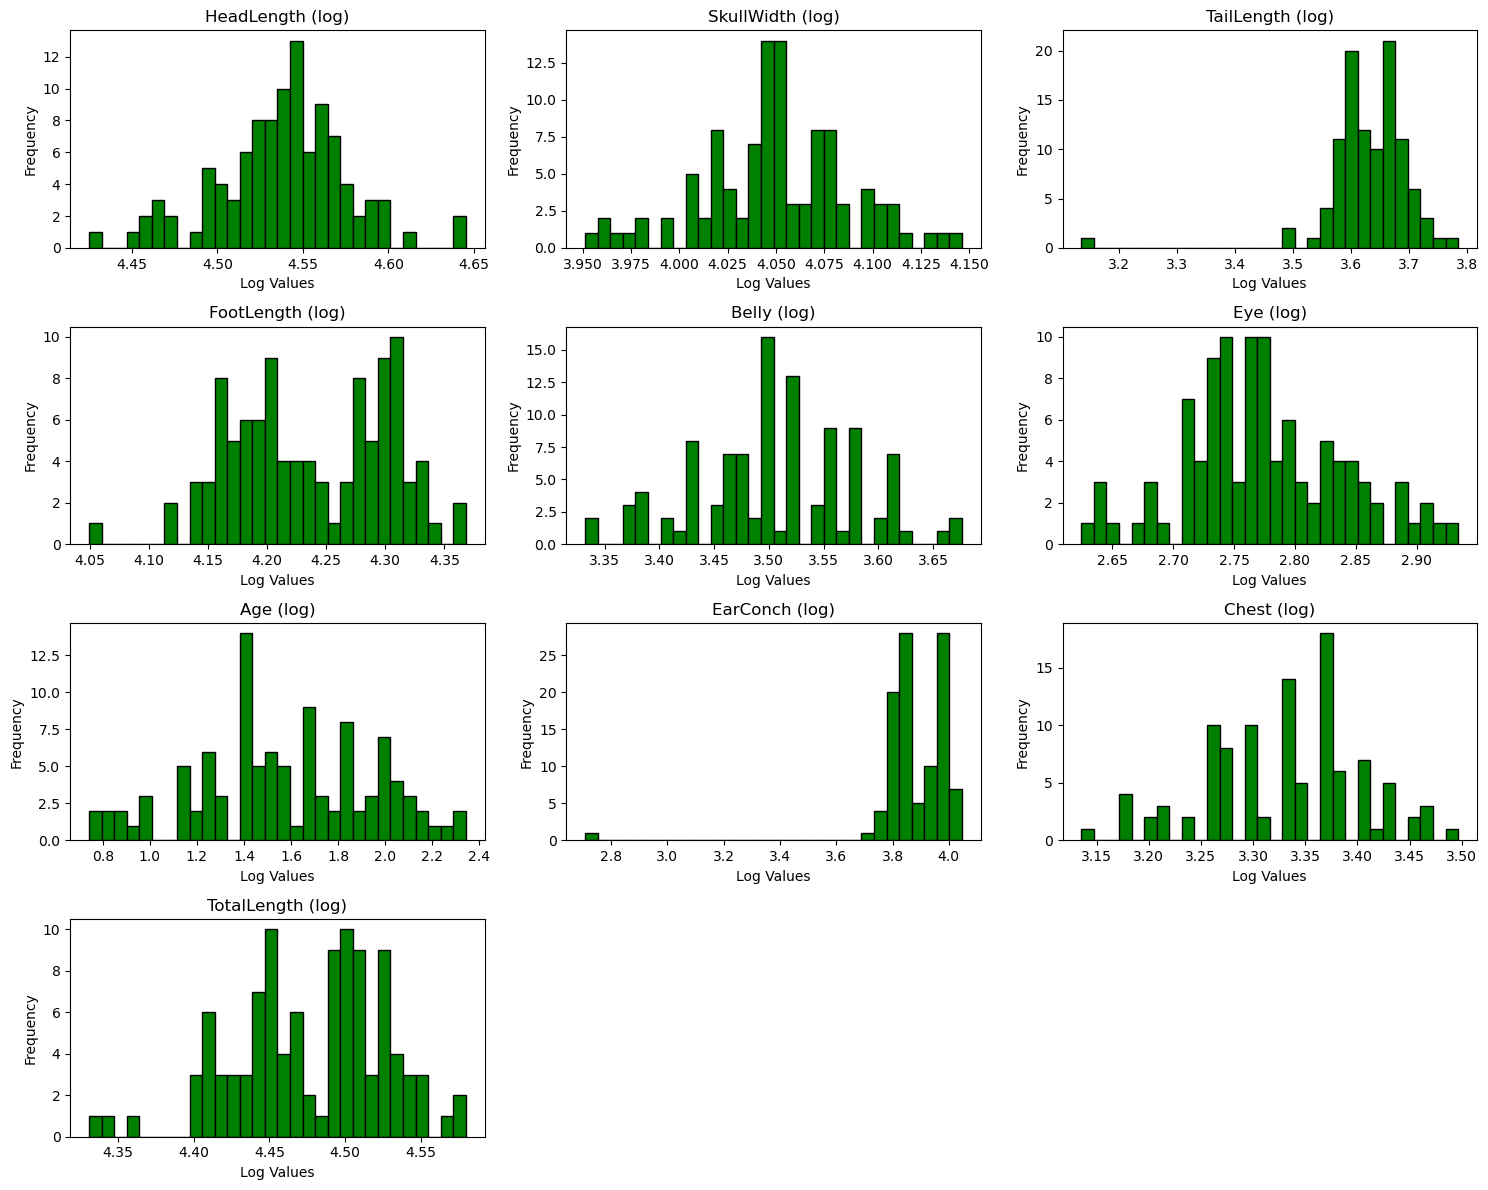

In [305]:
# Applying log transformation to fix skewness


df['HeadLength_log'] = np.log(df['HeadLength'] + 1)
df['SkullWidth_log'] = np.log(df['SkullWidth'] + 1)
df['TailLength_log'] = np.log(df['TailLength'] + 1)
df['FootLength_log'] = np.log(df['FootLength'] + 1)
df['Belly_log'] = np.log(df['Belly'] + 1)
df['Eye_log'] = np.log(df['Eye'] + 1)
df['Age_log'] = np.log(df['Age'] + 1)
df['EarConch_log'] = np.log(df['EarConch'] + 1)
df['Chest_log'] = np.log(df['Chest'] + 1)
df['TotalLength_log'] = np.log(df['TotalLength'] + 1)

# Displaying histogram after log transformation
plt.figure(figsize=(15, 12))

# HeadLength
plt.subplot(4, 3, 1)
plt.hist(df['HeadLength_log'], bins=30, color='green', edgecolor='black')
plt.title('HeadLength (log)')
plt.xlabel('Log Values')
plt.ylabel('Frequency')

# SkullWidth
plt.subplot(4, 3, 2)
plt.hist(df['SkullWidth_log'], bins=30, color='green', edgecolor='black')
plt.title('SkullWidth (log)')
plt.xlabel('Log Values')
plt.ylabel('Frequency')

# TailLength
plt.subplot(4, 3, 3)
plt.hist(df['TailLength_log'], bins=30, color='green', edgecolor='black')
plt.title('TailLength (log)')
plt.xlabel('Log Values')
plt.ylabel('Frequency')

# FootLength
plt.subplot(4, 3, 4)
plt.hist(df['FootLength_log'], bins=30, color='green', edgecolor='black')
plt.title('FootLength (log)')
plt.xlabel('Log Values')
plt.ylabel('Frequency')

# Belly
plt.subplot(4, 3, 5)
plt.hist(df['Belly_log'], bins=30, color='green', edgecolor='black')
plt.title('Belly (log)')
plt.xlabel('Log Values')
plt.ylabel('Frequency')

# Eye
plt.subplot(4, 3, 6)
plt.hist(df['Eye_log'], bins=30, color='green', edgecolor='black')
plt.title('Eye (log)')
plt.xlabel('Log Values')
plt.ylabel('Frequency')

# Age
plt.subplot(4, 3, 7)
plt.hist(df['Age_log'], bins=30, color='green', edgecolor='black')
plt.title('Age (log)')
plt.xlabel('Log Values')
plt.ylabel('Frequency')

# EarConch
plt.subplot(4, 3, 8)
plt.hist(df['EarConch_log'], bins=30, color='green', edgecolor='black')
plt.title('EarConch (log)')
plt.xlabel('Log Values')
plt.ylabel('Frequency')

# Chest
plt.subplot(4, 3, 9)
plt.hist(df['Chest_log'], bins=30, color='green', edgecolor='black')
plt.title('Chest (log)')
plt.xlabel('Log Values')
plt.ylabel('Frequency')

# TotalLength
plt.subplot(4, 3, 10)
plt.hist(df['TotalLength_log'], bins=30, color='green', edgecolor='black')
plt.title('TotalLength (log)')
plt.xlabel('Log Values')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()




In [307]:
# Calculating skewness after log transformation
skewness_possum_after_log = df[['HeadLength_log', 'SkullWidth_log', 'TailLength_log', 
                                'FootLength_log', 'Belly_log', 'Eye_log', 'Age_log', 
                                'EarConch_log', 'Chest_log', 'TotalLength_log']].skew()

print("Skewness of log-transformed possum data:\n", skewness_possum_after_log)


Skewness of log-transformed possum data:
 HeadLength_log    -0.211435
SkullWidth_log    -0.131713
TailLength_log    -3.324180
FootLength_log    -0.149090
Belly_log         -0.137950
Eye_log            0.206412
Age_log           -0.156636
EarConch_log      -5.363804
Chest_log         -0.241779
TotalLength_log   -0.421437
dtype: float64


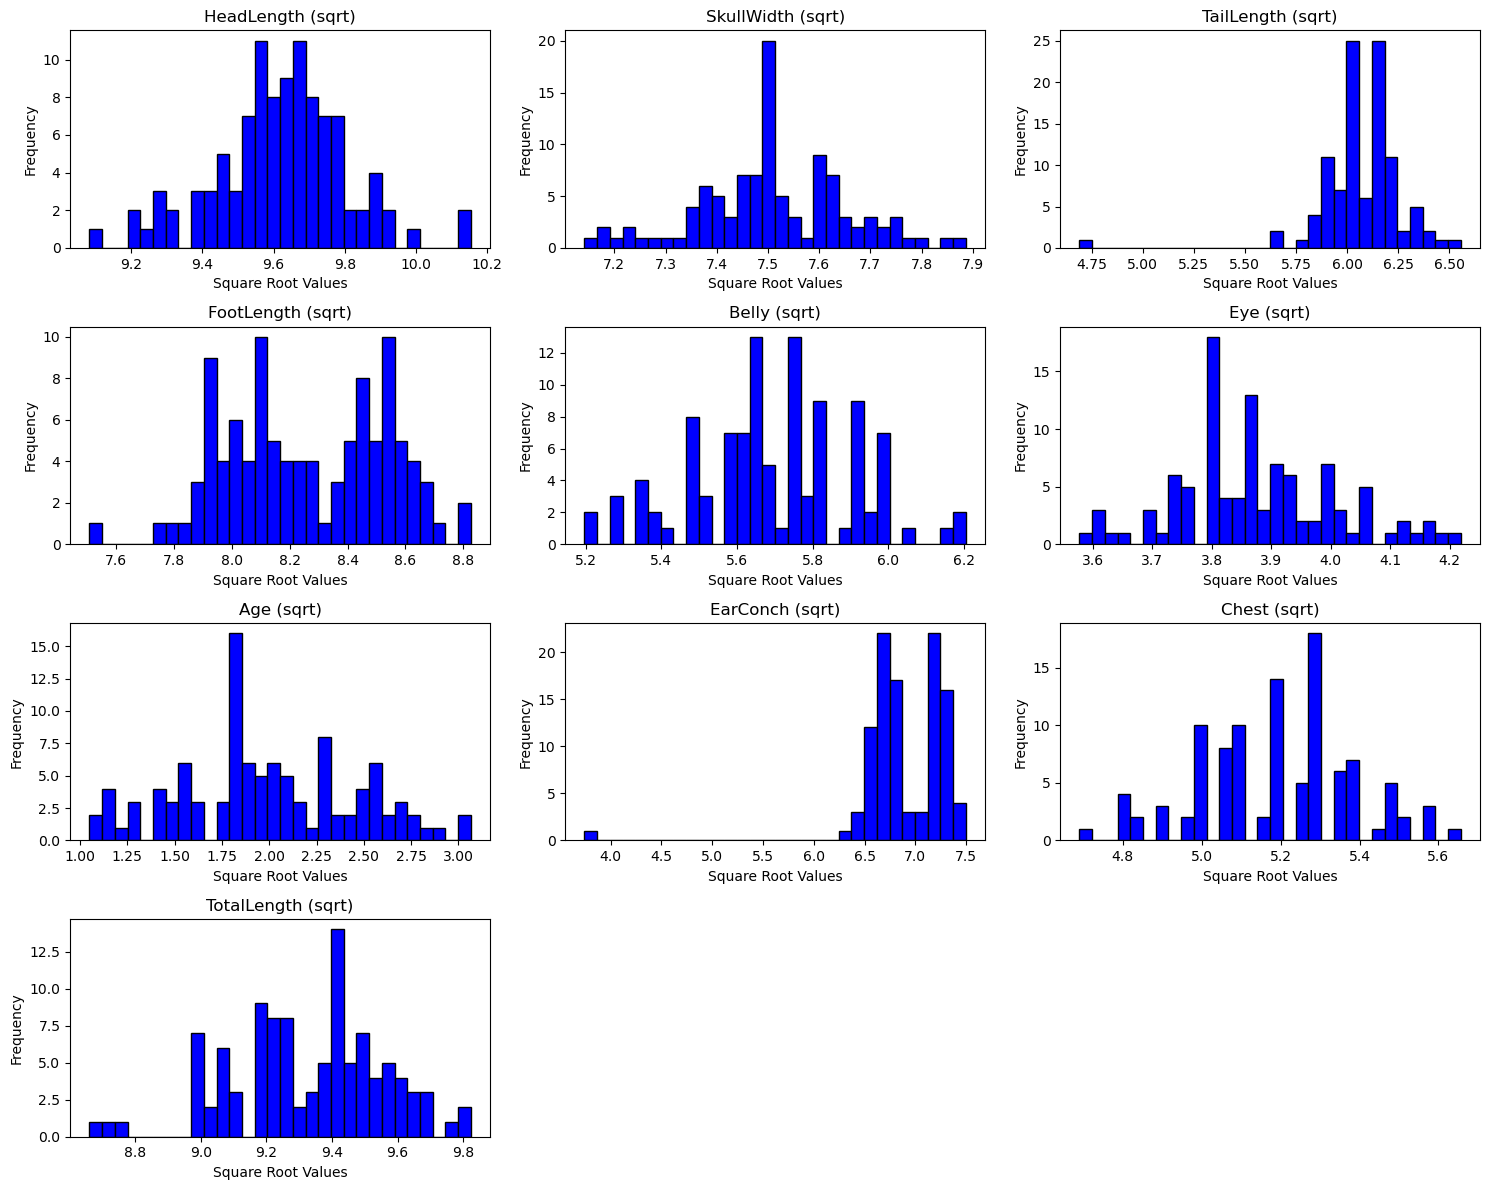

In [311]:


# Applying square root transformation
df['HeadLength_sqrt'] = np.sqrt(df['HeadLength'])
df['SkullWidth_sqrt'] = np.sqrt(df['SkullWidth'])
df['TailLength_sqrt'] = np.sqrt(df['TailLength'])
df['FootLength_sqrt'] = np.sqrt(df['FootLength'])
df['Belly_sqrt'] = np.sqrt(df['Belly'])
df['Eye_sqrt'] = np.sqrt(df['Eye'])
df['Age_sqrt'] = np.sqrt(df['Age'])
df['EarConch_sqrt'] = np.sqrt(df['EarConch'])
df['Chest_sqrt'] = np.sqrt(df['Chest'])
df['TotalLength_sqrt'] = np.sqrt(df['TotalLength'])

# Displaying histogram after square root transformation
plt.figure(figsize=(15, 12))

# HeadLength
plt.subplot(4, 3, 1)
plt.hist(df['HeadLength_sqrt'], bins=30, color='blue', edgecolor='black')
plt.title('HeadLength (sqrt)')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')

# SkullWidth
plt.subplot(4, 3, 2)
plt.hist(df['SkullWidth_sqrt'], bins=30, color='blue', edgecolor='black')
plt.title('SkullWidth (sqrt)')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')

# TailLength
plt.subplot(4, 3, 3)
plt.hist(df['TailLength_sqrt'], bins=30, color='blue', edgecolor='black')
plt.title('TailLength (sqrt)')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')

# FootLength
plt.subplot(4, 3, 4)
plt.hist(df['FootLength_sqrt'], bins=30, color='blue', edgecolor='black')
plt.title('FootLength (sqrt)')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')

# Belly
plt.subplot(4, 3, 5)
plt.hist(df['Belly_sqrt'], bins=30, color='blue', edgecolor='black')
plt.title('Belly (sqrt)')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')

# Eye
plt.subplot(4, 3, 6)
plt.hist(df['Eye_sqrt'], bins=30, color='blue', edgecolor='black')
plt.title('Eye (sqrt)')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')

# Age
plt.subplot(4, 3, 7)
plt.hist(df['Age_sqrt'], bins=30, color='blue', edgecolor='black')
plt.title('Age (sqrt)')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')

# EarConch
plt.subplot(4, 3, 8)
plt.hist(df['EarConch_sqrt'], bins=30, color='blue', edgecolor='black')
plt.title('EarConch (sqrt)')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')

# Chest
plt.subplot(4, 3, 9)
plt.hist(df['Chest_sqrt'], bins=30, color='blue', edgecolor='black')
plt.title('Chest (sqrt)')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')

# TotalLength
plt.subplot(4, 3, 10)
plt.hist(df['TotalLength_sqrt'], bins=30, color='blue', edgecolor='black')
plt.title('TotalLength (sqrt)')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


In [313]:
skewness_possum_after_sqrt = df[['HeadLength_sqrt', 'SkullWidth_sqrt', 'TailLength_sqrt', 
                                 'FootLength_sqrt', 'Belly_sqrt', 'Eye_sqrt', 'Age_sqrt', 
                                 'EarConch_sqrt', 'Chest_sqrt', 'TotalLength_sqrt']].skew()

print("Skewness of possum after square root transformation:\n", skewness_possum_after_sqrt)


Skewness of possum after square root transformation:
 HeadLength_sqrt    -0.133889
SkullWidth_sqrt    -0.068551
TailLength_sqrt    -2.680321
FootLength_sqrt    -0.093124
Belly_sqrt         -0.041546
Eye_sqrt            0.292546
Age_sqrt            0.125082
EarConch_sqrt      -3.783784
Chest_sqrt         -0.152008
TotalLength_sqrt   -0.353939
dtype: float64


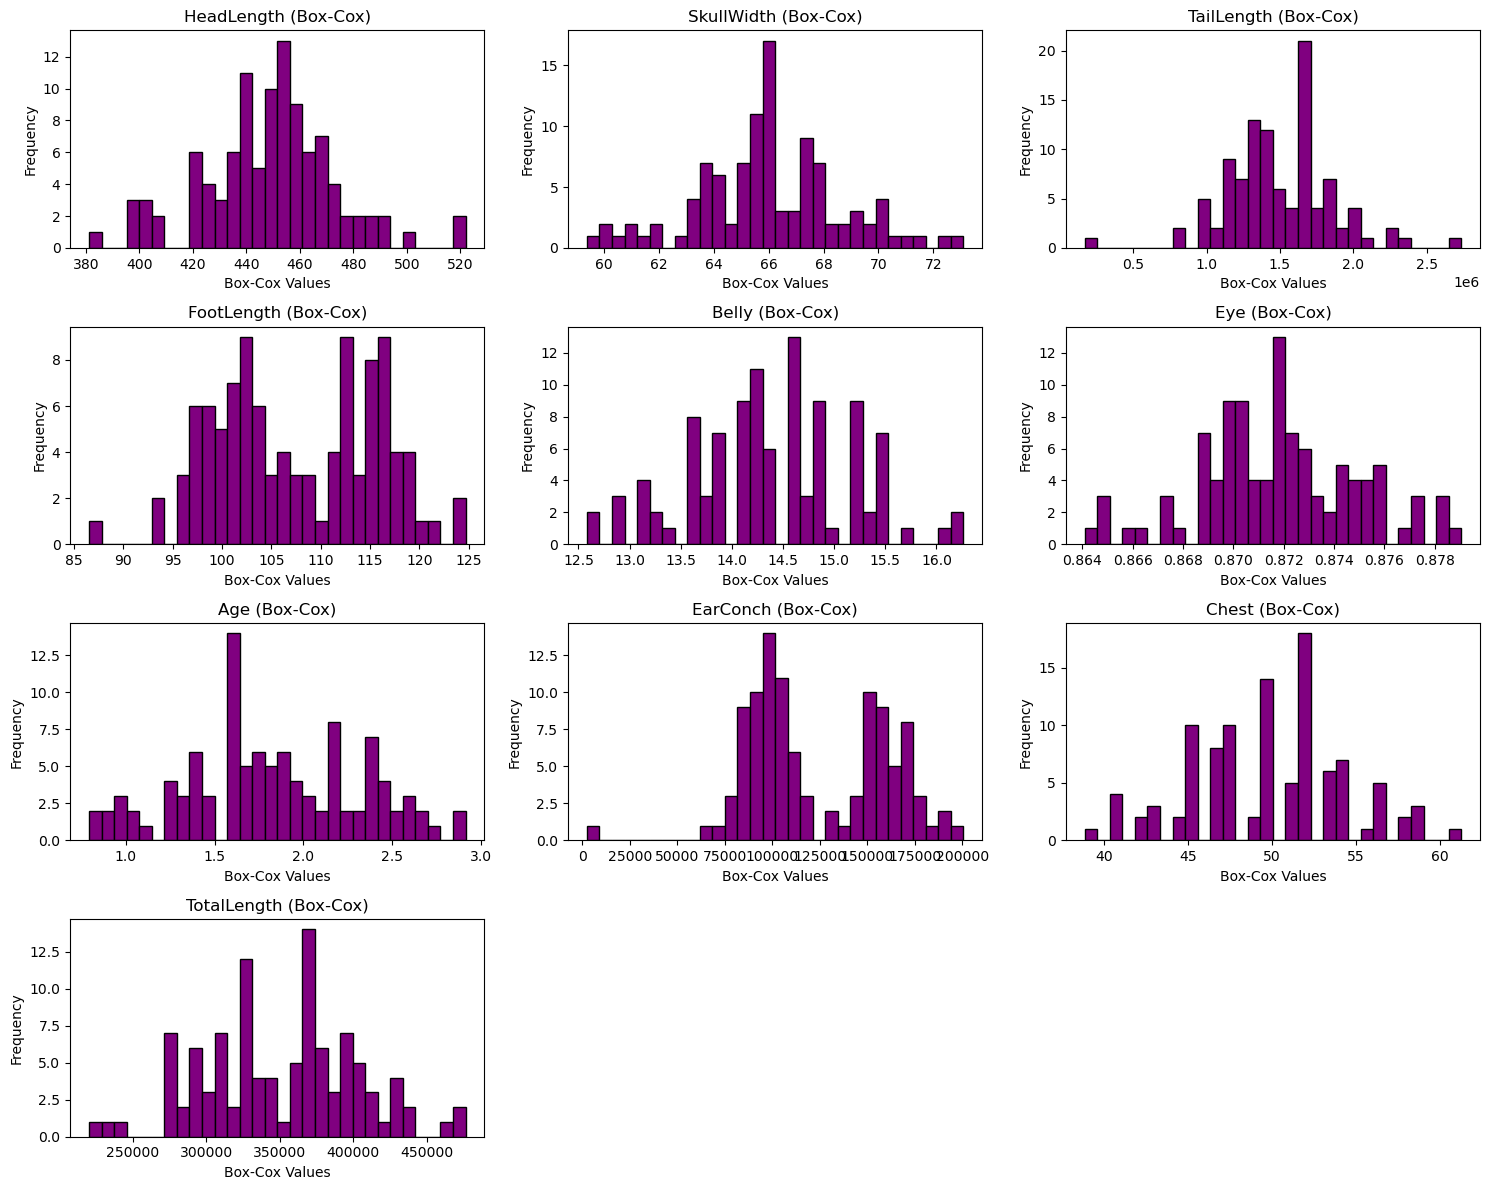

In [315]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Applying Box-Cox transformation (adding 1 to handle zeros)
df['HeadLength_boxcox'], _ = stats.boxcox(df['HeadLength'] + 1)
df['SkullWidth_boxcox'], _ = stats.boxcox(df['SkullWidth'] + 1)
df['TailLength_boxcox'], _ = stats.boxcox(df['TailLength'] + 1)
df['FootLength_boxcox'], _ = stats.boxcox(df['FootLength'] + 1)
df['Belly_boxcox'], _ = stats.boxcox(df['Belly'] + 1)
df['Eye_boxcox'], _ = stats.boxcox(df['Eye'] + 1)
df['Age_boxcox'], _ = stats.boxcox(df['Age'] + 1)
df['EarConch_boxcox'], _ = stats.boxcox(df['EarConch'] + 1)
df['Chest_boxcox'], _ = stats.boxcox(df['Chest'] + 1)
df['TotalLength_boxcox'], _ = stats.boxcox(df['TotalLength'] + 1)

# Displaying histogram after Box-Cox transformation
plt.figure(figsize=(15, 12))

# HeadLength
plt.subplot(4, 3, 1)
plt.hist(df['HeadLength_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('HeadLength (Box-Cox)')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')

# SkullWidth
plt.subplot(4, 3, 2)
plt.hist(df['SkullWidth_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('SkullWidth (Box-Cox)')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')

# TailLength
plt.subplot(4, 3, 3)
plt.hist(df['TailLength_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('TailLength (Box-Cox)')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')

# FootLength
plt.subplot(4, 3, 4)
plt.hist(df['FootLength_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('FootLength (Box-Cox)')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')

# Belly
plt.subplot(4, 3, 5)
plt.hist(df['Belly_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('Belly (Box-Cox)')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')

# Eye
plt.subplot(4, 3, 6)
plt.hist(df['Eye_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('Eye (Box-Cox)')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')

# Age
plt.subplot(4, 3, 7)
plt.hist(df['Age_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('Age (Box-Cox)')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')

# EarConch
plt.subplot(4, 3, 8)
plt.hist(df['EarConch_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('EarConch (Box-Cox)')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')

# Chest
plt.subplot(4, 3, 9)
plt.hist(df['Chest_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('Chest (Box-Cox)')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')

# TotalLength
plt.subplot(4, 3, 10)
plt.hist(df['TotalLength_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('TotalLength (Box-Cox)')
plt.xlabel('Box-Cox Values')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


In [319]:
# Calculating skewness for each Box-Cox transformed column
skewness_possum_after_boxcox = df[['HeadLength_boxcox', 'SkullWidth_boxcox', 'TailLength_boxcox',
                                   'FootLength_boxcox', 'Belly_boxcox', 'Eye_boxcox', 'Age_boxcox',
                                   'EarConch_boxcox', 'Chest_boxcox', 'TotalLength_boxcox']].skew()

print("Skewness of possum after Box-Cox transformation:\n", skewness_possum_after_boxcox)



Skewness of possum after Box-Cox transformation:
 HeadLength_boxcox     0.013735
SkullWidth_boxcox     0.003262
TailLength_boxcox     0.227243
FootLength_boxcox    -0.023172
Belly_boxcox         -0.003451
Eye_boxcox            0.001957
Age_boxcox           -0.013984
EarConch_boxcox      -0.008390
Chest_boxcox         -0.010387
TotalLength_boxcox   -0.017481
dtype: float64


# Answer to Section 3 (6 Marks)

## Hypothesis 1 (all the codes in one cell) 

only title of H0 & H1:

In [341]:
from scipy import stats
## Step 1: State the Null Hypothesis and the Alternative Hypothesis
#Null Hypothesis (H0): The mean age of a possum is 5 yrs old. (μ = 5)
#Alternative Hypothesis (Ha):  The mean age of a possum is different from 5 yrs old. (μ ≠ 5)

# Step 2: Hypothesized population mean age (5 years)
population_mean = 5  

# Step 3: Perform a one-sample t-test
t_statistic, p_value = stats.ttest_1samp(df['Age'].dropna(), population_mean)

print("t-statistic:", t_statistic)
print("p-value:", p_value)

# Step 4: Decide based on the p-value
alpha = 0.05
if p_value < alpha:
    print("Reject H₀: The mean age of possums is significantly different from 5 years old.")
else:
    print("Fail to reject H₀: No significant evidence that the mean age differs from 5 years old.")


t-statistic: -4.399152144603303
p-value: 2.6556491959989498e-05
Reject H₀: The mean age of possums is significantly different from 5 years old.


## Hypothesis 2 (all the codes in one cell) 

In [345]:
# Separate HeadLength by gender
male_head = df[df['Gender'] == 'm']['HeadLength'].dropna()
female_head = df[df['Gender'] == 'f']['HeadLength'].dropna()

# Perform a two-sample independent t-test
t_statistic, p_value = stats.ttest_ind(male_head, female_head, alternative='greater')  # one-tailed: male > female

print("t-statistic:", t_statistic)
print("p-value:", p_value)

# Decision based on significance level
alpha = 0.05
if p_value < alpha:
    print("Reject H₀: Males have significantly larger HeadLength than females.")
else:
    print("Fail to reject H₀: No significant evidence that males have larger HeadLength than females.")


t-statistic: 1.1312913404821716
p-value: 0.1302926567722356
Fail to reject H₀: No significant evidence that males have larger HeadLength than females.


Only title of H0 & H1:

# Answer to Section 4 (9 Marks) (add as many cell as needed)

# simple regression 1 (TailLength and FootLength)

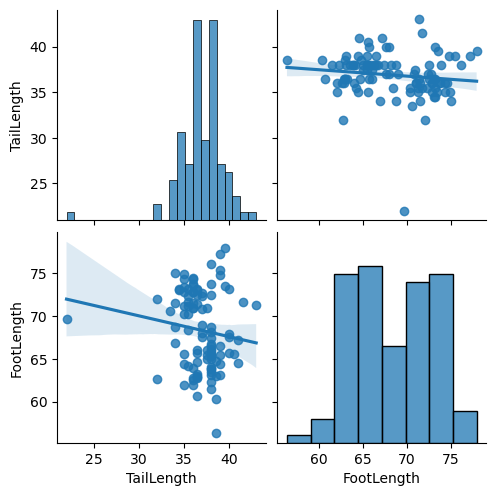

In [353]:
sns.pairplot(ols_data, kind="reg") 
plt.show()

In [355]:


# Subset Data
ols_data = df[["TailLength", "FootLength"]]

# Write out formula  = Y~X
ols_formula = "TailLength ~ FootLength"

# Import ols function
from statsmodels.formula.api import ols
# Build OLS, fit model to data
OLS = ols(formula = ols_formula, data = ols_data)
model = OLS.fit()
model.summary()




<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             TailLength   R-squared:                       0.017
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     1.771
Date:                Tue, 14 Oct 2025   Prob (F-statistic):              0.186
Time:                        20:19:04   Log-Likelihood:                -238.69
No. Observations:                 104   AIC:                             481.4
Df Residuals:                     102   BIC:                             486.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     41.6911      3.612     11.542      0.000      34.527      48.856
FootLength    -0.0702      0.053     -1.331      0.186      -0.175       0.034
==============================================================================
Omnibus:                       72.350   Durbin-Watson:                   1.435
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              736.898
Skew:                          -2.006   Prob(JB):                    9.65e-161
Kurtosis:                      15.408   Cond. No.                     1.04e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.04e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
# simple regression 2 (SkullWidth vs HeadLength)

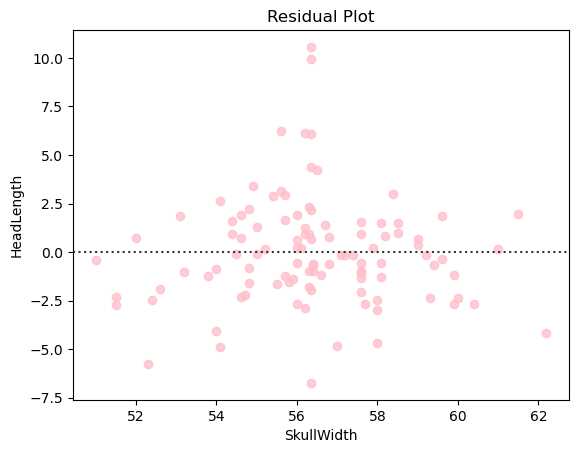

In [375]:
sns.residplot(x="SkullWidth", y="HeadLength", data=df, color="pink")
plt.title("Residual Plot")
plt.show()


In [385]:
# Subset Data
ols_data = df[["SkullWidth", "HeadLength"]]

# Write out formula  = Y~X
ols_formula = "HeadLength ~ SkullWidth"

# Import ols function
from statsmodels.formula.api import ols
# Build OLS, fit model to data
OLS = ols(formula = ols_formula, data = ols_data)
model = OLS.fit()
model.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             HeadLength   R-squared:                       0.403
Model:                            OLS   Adj. R-squared:                  0.397
Method:                 Least Squares   F-statistic:                     68.85
Date:                Tue, 14 Oct 2025   Prob (F-statistic):           4.61e-13
Time:                        20:46:47   Log-Likelihood:                -253.05
No. Observations:                 104   AIC:                             510.1
Df Residuals:                     102   BIC:                             515.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     33.2693      7.154      4.650      0.000      19.078      47.460
SkullWidth     1.0518      0.127      8.297      0.000       0.800       1.303
==============================================================================
Omnibus:                       23.930   Durbin-Watson:                   1.754
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               45.471
Skew:                           0.926   Prob(JB):                     1.34e-10
Kurtosis:                       5.658   Cond. No.                     1.48e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.48e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
# simple regression 3 (Belly vs chest)

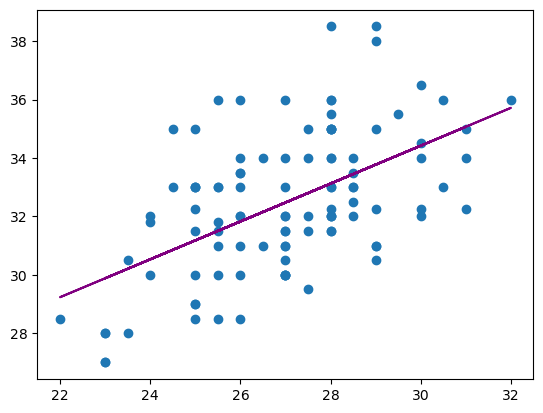

In [373]:
plt.scatter(df["Chest"], df["Belly"])
plt.plot(df["Chest"], model.predict(df["Chest"]), color="purple")
plt.show()



In [367]:
# Subset Data
ols_data = df[["Chest", "Belly"]]

# Write out formula  = Y~X
ols_formula = "Belly ~ Chest"

# Import ols function
from statsmodels.formula.api import ols
# Build OLS, fit model to data
OLS = ols(formula = ols_formula, data = ols_data)
model = OLS.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Belly   R-squared:                       0.294
Model:                            OLS   Adj. R-squared:                  0.287
Method:                 Least Squares   F-statistic:                     42.46
Date:                Tue, 14 Oct 2025   Prob (F-statistic):           2.78e-09
Time:                        20:33:04   Log-Likelihood:                -221.99
No. Observations:                 104   AIC:                             448.0
Df Residuals:                     102   BIC:                             453.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     14.9715      2.694      5.558      0.000       9.629      20.314
Chest          0.6483      0.099      6.516      0.000       0.451       0.846
==============================================================================
Omnibus:                        4.646   Durbin-Watson:                   1.975
Prob(Omnibus):                  0.098   Jarque-Bera (JB):                4.475
Skew:                           0.454   Prob(JB):                        0.107
Kurtosis:                       2.545   Cond. No.                         361.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
# simple regression 4 (TotalLength vs Age)

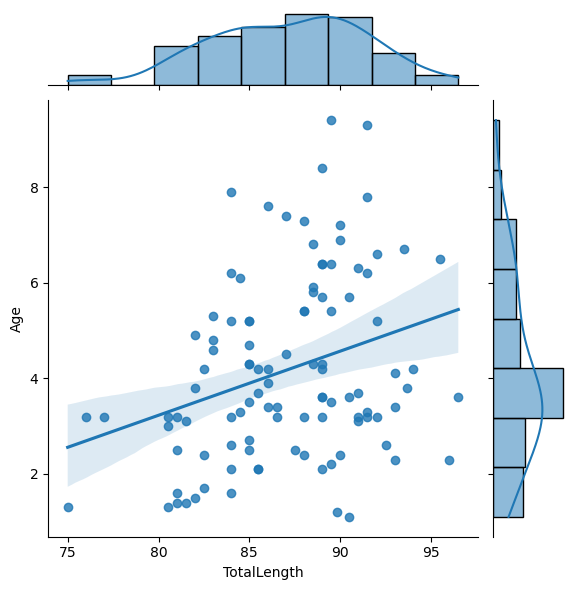

In [391]:
sns.jointplot(x="TotalLength", y="Age", data=df, kind="reg")
plt.show()



In [389]:
# Subset Data 
ols_data = df[["TotalLength", "Age"]]

# Write out formula  = Y~X
ols_formula = "Age ~ TotalLength"

# Import ols function
from statsmodels.formula.api import ols
# Build OLS, fit model to data
OLS = ols(formula = ols_formula, data = ols_data)
model = OLS.fit()
model.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    Age   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     10.32
Date:                Tue, 14 Oct 2025   Prob (F-statistic):            0.00177
Time:                        20:52:04   Log-Likelihood:                -209.25
No. Observations:                 104   AIC:                             422.5
Df Residuals:                     102   BIC:                             427.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -7.5015      3.641     -2.061      0.042     -14.722      -0.281
TotalLength     0.1341      0.042      3.212      0.002       0.051       0.217
==============================================================================
Omnibus:                        4.698   Durbin-Watson:                   1.597
Prob(Omnibus):                  0.095   Jarque-Bera (JB):                4.760
Skew:                           0.504   Prob(JB):                       0.0925
Kurtosis:                       2.715   Cond. No.                     1.77e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.77e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

simple regression 3 (title)

In [ ]:
# simple regression 5 (Earconch vs Age)

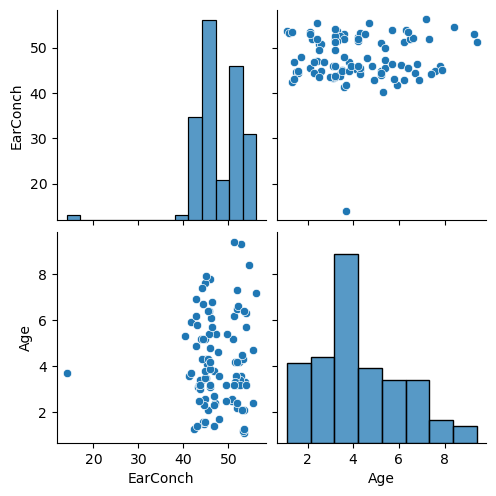

In [395]:


# Subset for just the two columns
subset_data = df[["EarConch", "Age"]].dropna()  # drop missing values

# Pairplot
sns.pairplot(subset_data)
plt.show()



In [393]:
# Subset Data 
ols_data = df[["EarConch", "Age"]]

# Write out formula  = Y~X
ols_formula = "Age ~ EarConch"

# Import ols function
from statsmodels.formula.api import ols
# Build OLS, fit model to data
OLS = ols(formula = ols_formula, data = ols_data)
model = OLS.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    Age   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.010
Method:                 Least Squares   F-statistic:                   0.02099
Date:                Tue, 14 Oct 2025   Prob (F-statistic):              0.885
Time:                        20:58:29   Log-Likelihood:                -214.25
No. Observations:                 104   AIC:                             432.5
Df Residuals:                     102   BIC:                             437.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      3.9299      1.715      2.291      0.024       0.528       7.332
EarConch       0.0052      0.036      0.145      0.885      -0.066       0.076
==============================================================================
Omnibus:                        6.145   Durbin-Watson:                   1.493
Prob(Omnibus):                  0.046   Jarque-Bera (JB):                6.344
Skew:                           0.591   Prob(JB):                       0.0419
Kurtosis:                       2.742   Cond. No.                         439.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

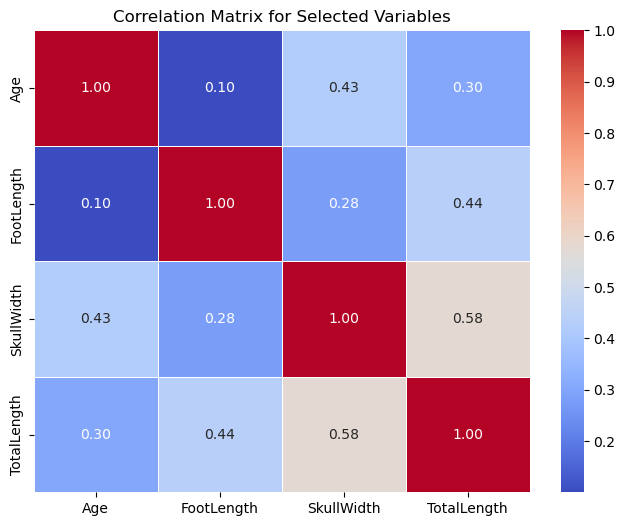

In [439]:


# Select only the columns used in your multiple regression
corr_vars = ['Age', 'FootLength', 'SkullWidth', 'TotalLength']

# Convert to numeric if needed
corr_df = df[corr_vars].apply(pd.to_numeric, errors='coerce')

# Drop rows with missing values
corr_df = corr_df.dropna()

# Compute correlation matrix
correlation_matrix = corr_df.corr()

# Set up the figure
plt.figure(figsize=(8, 6))

# Generate heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title('Correlation Matrix for Selected Variables')
plt.show()


In [441]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# Use X_clean without missing values and including the constant
# Exclude the constant when calculating VIF (optional, but usually constant is excluded)
X_vif = X_clean.drop(columns='const')  

# Create a DataFrame to store VIF values
vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns

# Calculate VIF for each feature
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

# Display VIF
print(vif_data)


      Feature         VIF
0         Age    6.337928
1  FootLength  230.790274
2  SkullWidth  244.721011


In [433]:
import statsmodels.api as sm
import pandas as pd

# Select predictors
X = df[['Age', 'FootLength', 'SkullWidth']].copy()

# Convert to numeric if necessary
X = X.apply(pd.to_numeric, errors='coerce')

# Target variable
y_total = pd.to_numeric(df['TotalLength'], errors='coerce')

# Combine and drop missing values
data = pd.concat([X, y_total], axis=1).dropna()

X_clean = data[['Age', 'FootLength', 'SkullWidth']]
X_clean = sm.add_constant(X_clean)  # add constant for intercept
y_clean = data['TotalLength']

# Fit the model
model_total = sm.OLS(y_clean, X_clean).fit()

# Show summary
print("Multiple regression for TotalLength:\n", model_total.summary())


Multiple regression for TotalLength:
                             OLS Regression Results                            
Dep. Variable:            TotalLength   R-squared:                       0.421
Model:                            OLS   Adj. R-squared:                  0.404
Method:                 Least Squares   F-statistic:                     24.25
Date:                Tue, 14 Oct 2025   Prob (F-statistic):           7.10e-12
Time:                        21:34:38   Log-Likelihood:                -270.63
No. Observations:                 104   AIC:                             549.3
Df Residuals:                     100   BIC:                             559.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         

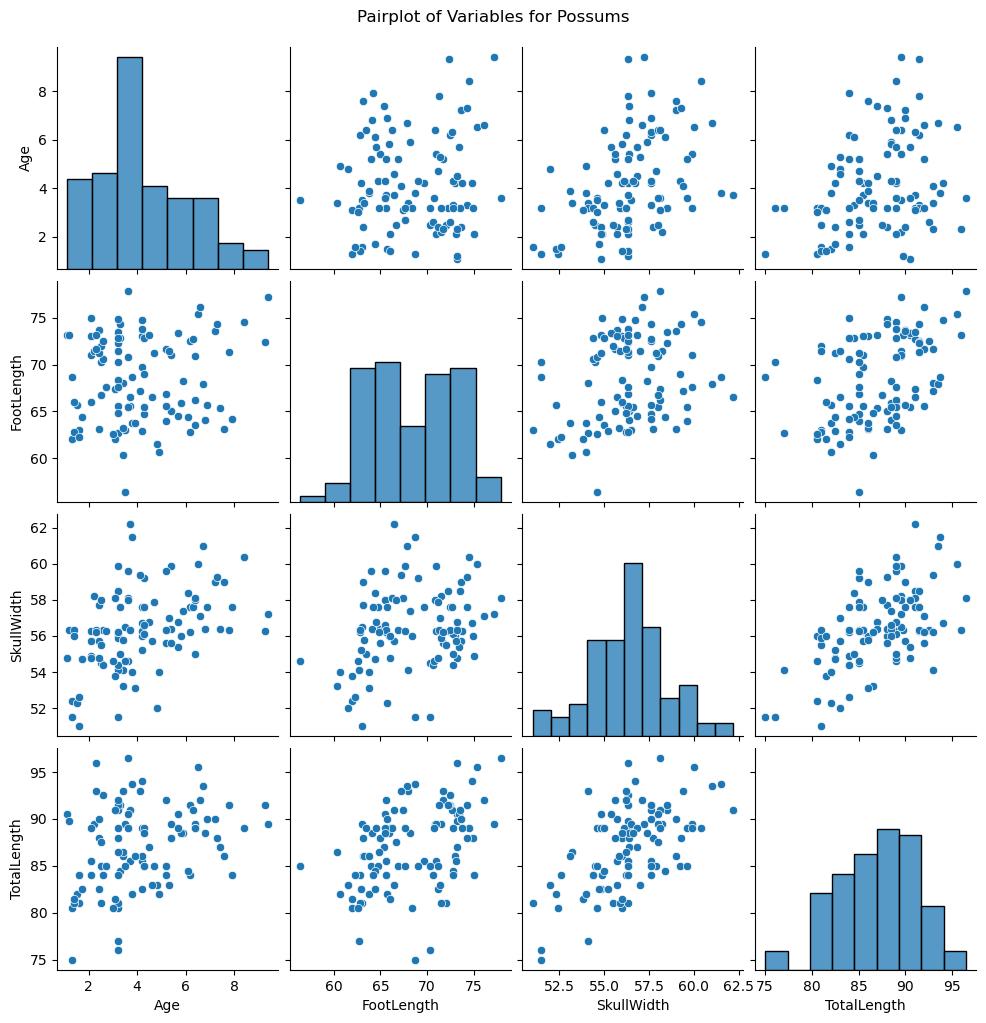

In [450]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select the same columns used in multiple regression
pairplot_vars = ['Age', 'FootLength', 'SkullWidth', 'TotalLength']

# Convert to numeric if needed and drop missing values
pairplot_df = df[pairplot_vars].apply(pd.to_numeric, errors='coerce').dropna()

# Create pairplot
sns.pairplot(pairplot_df, kind='scatter', height=2.5)
plt.suptitle("Pairplot of Variables for Possums", y=1.02)
plt.show()


In [455]:
df.to_csv('possum.csv.xlsx', index=False)